# Exploración reproducible: `spam_spanish`

Este notebook lee el CSV original sin modificarlo. El análisis completo se guarda en [`../reports/spam_spanish.md`](../reports/spam_spanish.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
while not (HERE / 'notebooks' / 'exploracion-datasets' / 'dataset_audit.py').exists():
    if HERE.parent == HERE:
        raise FileNotFoundError('No se encontró la raíz del repositorio')
    HERE = HERE.parent
sys.path.insert(0, str(HERE / 'notebooks' / 'exploracion-datasets'))
from dataset_audit import DATASETS, analyze_dataset, load_dataset, combined_text
spec = next(item for item in DATASETS if item.slug == 'spam_spanish')
df = load_dataset(spec)
result = analyze_dataset(spec)
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Objetivo: {spec.target}')

Dimensiones: 15,016 filas × 2 columnas
Objetivo: labels


## Esquema, tipos y nulos

In [2]:
schema = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': (df.isna().mean() * 100).round(2),
})
display(schema)

,tipo,nulos,nulos_pct
text,str,0,0.0
labels,int64,0,0.0


## Clases, duplicados y conflictos

,registros
labels,
1,7982
0,7034


Filas duplicadas: 266
Filas con texto repetido: 416
Textos con etiquetas conflictivas: 0


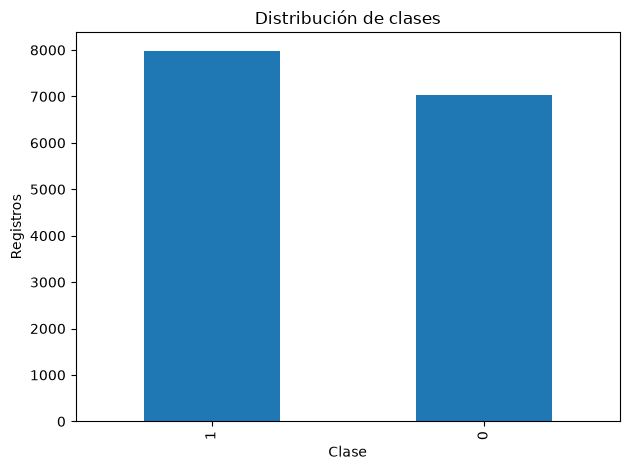

In [3]:
display(df[spec.target].value_counts(dropna=False).rename('registros').to_frame())
print('Filas duplicadas:', result['full_row_duplicates'])
print('Filas con texto repetido:', result['text_duplicates'])
print('Textos con etiquetas conflictivas:', result['conflicting_normalized_texts'])
df[spec.target].astype(str).value_counts().plot(kind='bar', title='Distribución de clases')
plt.xlabel('Clase'); plt.ylabel('Registros'); plt.tight_layout(); plt.show()

## Longitud, idioma y patrones

,caracteres,palabras
count,15016.000000,15016.000000
min,14.000000,0.000000
q25,66.000000,10.000000
median,78.000000,12.000000
mean,79.778703,12.305008
q75,91.000000,14.000000
p95,114.000000,18.000000
max,1320.000000,149.000000


Idiomas declarados o estimados: {'es': 12244, 'indeterminado': 2751, 'en': 21}
Filas con URL/correo/teléfono: 707 94 192


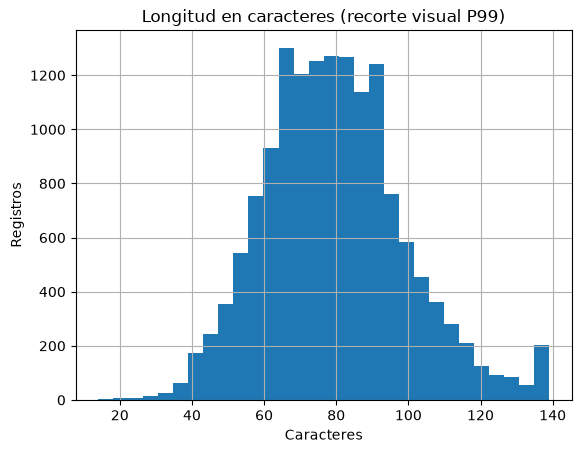

In [4]:
display(pd.DataFrame({
    'caracteres': result['length_characters'],
    'palabras': result['length_words'],
}))
print('Idiomas declarados o estimados:', result['declared_languages'] or result['language_heuristic'])
print('Filas con URL/correo/teléfono:', result['rows_with_url_pattern'], result['rows_with_email_pattern'], result['rows_with_phone_pattern'])
text = combined_text(df, spec.text_columns)
text.str.len().clip(upper=text.str.len().quantile(.99)).hist(bins=30)
plt.title('Longitud en caracteres (recorte visual P99)'); plt.xlabel('Caracteres'); plt.ylabel('Registros'); plt.show()

## Ejemplos sanitizados y conclusión

In [5]:
for label, examples in result['examples'].items():
    print(f'\nClase {label}')
    for example in examples:
        print('-', example)


Clase 0
- Hola, ¿cómo estás? Me gustaría concertar una cita para la próxima semana.
- El evento de today fue un éxito. Gracias por tu apoyo y par la próxima!,.

Clase 1
- ¡Esquema piramidal! Invita a 3 personas y gane $5000. ¡Comparte este mensaje ahora!
- ¡Felicidades! Has ganado un viaje a Puerto Rico. Clic en este enlace para confirmar


La interpretación, riesgos de fuga, sesgos, utilidad para Random Forest y estrategia de combinación están documentados en [`../reports/spam_spanish.md`](../reports/spam_spanish.md).